# Topic 16 Worked Example: Lasso and Ridge on the Video-Game Films

**ECON 3916 · the midterm example, one topic later**

The midterm example asked whether video-game films score better with critics when the director was young
when the game came out. Its answer: the age coefficient is small, and its confidence interval includes zero.

Topic 16 gives two new tools, and you already know both. **Ridge** is OLS with a charge on the size of
every coefficient. **Lasso** is OLS with a charge that pushes some coefficients all the way to zero, so
it picks variables for you. This notebook asks two questions with them, on the same 57 films:

1. **Prediction.** Given what is known before a film opens, can a penalized model predict its critics'
   score better than the midterm's three-variable model?
2. **The midterm question.** Can a penalty change the answer about the director's age?

They have different answers, and the gap between them is what this notebook is about.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression, LassoCV, RidgeCV, lasso_path
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold
import warnings
from sklearn.exceptions import ConvergenceWarning
# The smallest penalties on the grid barely shrink 23 features on 57 films, and the lasso solver warns there.
# Cross-validation never chooses those penalties; the check at the end of Part 4 fits the chosen one with warnings as errors.
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# Opened in Colab from GitHub? Then download the one data file this notebook reads.
import os, urllib.request
os.makedirs("data", exist_ok=True)
if not os.path.exists("data/movies_sample.csv"):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/RyanPiao/econ3916-midterm-example/main/data/movies_sample.csv",
                               "data/movies_sample.csv")

## Part 1: The Data and the Candidate Features

`data/movies_sample.csv` is the midterm sample: the 57 films left after the midterm notebook's cleaning
(2026 releases dropped, and films with no score, no director's birth year or no game year dropped). One row is one film.

In [2]:
films = pd.read_csv("data/movies_sample.csv")
print(films.shape)
print(films[["title", "year", "rt", "age_game", "animated"]].head(3).to_string(index=False))

(57, 13)
            title  year   rt  age_game  animated
Super Mario Bros.  1993 26.0      26.0         0
    Double Dragon  1994 12.0      24.0         0
   Street Fighter  1994 17.0      44.0         0


A penalty only helps when there are many candidate variables. The midterm model has three
(age when the game came out, release year, animated), so here we build a longer list. **Every candidate
is known before the film opens**, because the job is to predict a score a film has not received yet:

- the three midterm variables, plus how long the game had been out (`lag`) and the log budget
  (filled with the median when missing, with a 0/1 flag saying it was missing);
- squared terms and three interactions, the shapes a line cannot bend into;
- the midterm's franchise flag (`later_film`);
- 0/1 indicators for the five most common game publishers and the five most common distributors.

Two things are left out on purpose. The director's age at release is exactly age at the game plus `lag`,
so including all three would make OLS impossible (perfect collinearity, Topic 13). And nothing measured
after release goes in: not the review count, not the box office, not the Metacritic score. Part 6 shows
what happens if you break that rule.

In [3]:
X = pd.DataFrame({"age_game": films["age_game"], "year": films["year"], "animated": films["animated"],
                  "lag": films["lag"], "later_film": films["later_film"]})
X["log_budget"] = films["log_budget"].fillna(films["log_budget"].median())
X["budget_missing"] = films["log_budget"].isna().astype(int)
X["age_sq"] = X["age_game"] ** 2
X["year_sq"] = (X["year"] - 2010) ** 2          # centred on 2010 so the square is not almost a copy of year
X["lag_sq"] = X["lag"] ** 2
X["anim_x_year"] = X["animated"] * (X["year"] - 2010)
X["anim_x_age"] = X["animated"] * X["age_game"]
X["age_x_year"] = X["age_game"] * (X["year"] - 2010)
for name in films["publisher"].value_counts().index[:5]:
    X["pub_" + name.split()[0]] = (films["publisher"] == name).astype(int)
for name in films["distributor"].value_counts().index[:5]:
    X["dist_" + name.split()[0]] = (films["distributor"] == name).astype(int)
y = films["rt"].to_numpy()
MAIN = ["age_game", "year", "animated"]          # the midterm model
print(X.shape[1], "candidate features for", len(y), "films")
print(list(X.columns))

23 candidate features for 57 films
['age_game', 'year', 'animated', 'lag', 'later_film', 'log_budget', 'budget_missing', 'age_sq', 'year_sq', 'lag_sq', 'anim_x_year', 'anim_x_age', 'age_x_year', 'pub_Capcom', 'pub_Sega', 'pub_Eidos', 'pub_Ubisoft', 'pub_Sony', 'dist_Sony', 'dist_20th', 'dist_Paramount', 'dist_Universal', 'dist_Warner']


## Part 2: One Scorecard for Every Model

We judge every model the same way: its error on films it did not see (Topic 15). Split the 57 films
into 10 folds, fit on 9, predict the tenth, and repeat with 20 different shuffles so one lucky split
cannot decide the ranking. The score is the root mean squared error in Rotten Tomatoes points.

Two details matter. Every model is a pipeline that standardizes the features first, because a penalty
on coefficient size is only fair when the features are on one scale. And the penalized models choose
their penalty with their own cross-validation **inside** each training fold, so the held-out films
never help choose it.

In [4]:
PENALTIES = np.logspace(-2, 3, 60)              # the grid of penalties to try (sklearn calls the penalty alpha)

def ols():
    return make_pipeline(StandardScaler(), LinearRegression())
def ridge():
    return make_pipeline(StandardScaler(), RidgeCV(alphas=PENALTIES))
def lasso():
    return make_pipeline(StandardScaler(), LassoCV(alphas=PENALTIES, cv=5, max_iter=50_000, random_state=0))

def cv_rmse(make_model, cols, repeats=20):
    """Held-out RMSE for each of `repeats` shuffles of 10-fold CV. make_model=None predicts the training mean."""
    out = []
    for seed in range(repeats):
        sq_err = []
        for train, test in KFold(10, shuffle=True, random_state=seed).split(X):
            if make_model is None:
                pred = np.full(len(test), y[train].mean())
            else:
                pred = make_model().fit(X.iloc[train][cols], y[train]).predict(X.iloc[test][cols])
            sq_err += list((y[test] - pred) ** 2)
        out.append(np.sqrt(np.mean(sq_err)))
    return np.array(out)

ALL = list(X.columns)
score = {
    "Predict the average": cv_rmse(None, ALL),
    "OLS, midterm model (3)": cv_rmse(ols, MAIN),
    f"OLS, all {len(ALL)}": cv_rmse(ols, ALL),
}
for name, r in score.items():
    print(f"{name:26} held-out RMSE {r.mean():5.2f}")

Predict the average        held-out RMSE 24.53
OLS, midterm model (3)     held-out RMSE 20.24
OLS, all 23                held-out RMSE 26.71


Read the third line against the first. OLS with every feature predicts **worse than guessing the
average score** for every film. With 57 films and this many coefficients, OLS fits the training folds'
noise and carries it to the held-out films: Topic 15's overfitting, much bigger than the squared term
in the midterm's Section 4.

## Part 3: Ridge, Every Coefficient Shrunk

Ridge minimizes the OLS sum of squared residuals **plus** the penalty times the sum of squared
coefficients. At a penalty of zero it is OLS. As the penalty grows, every coefficient is pulled toward
zero, and none reaches it. The plot shows each standardized coefficient (the change in score for a one-standard-deviation change in
the feature, so features on different scales share one axis) as the penalty grows, with age
when the game came out in black.

Penalty chosen on all 57 films: 36.3
Ridge, all 23              held-out RMSE 19.22
Ridge, midterm model (3)   held-out RMSE 20.16


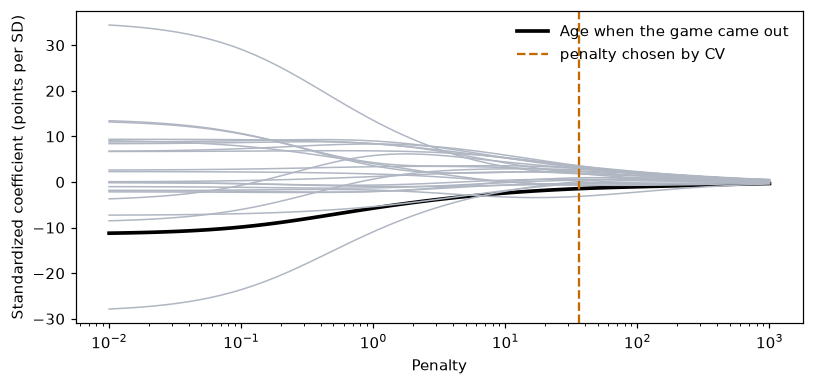

In [5]:
Z = StandardScaler().fit_transform(X)
path = []
for a in PENALTIES:
    m = make_pipeline(StandardScaler(), RidgeCV(alphas=[a])).fit(X, y)
    path.append(m[-1].coef_)
path = np.array(path)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for j, name in enumerate(ALL):
    ax.plot(PENALTIES, path[:, j], color="black" if name == "age_game" else "#B0B7C3", lw=2.4 if name == "age_game" else 1,
            label="Age when the game came out" if name == "age_game" else None)
ridge_fit = ridge().fit(X, y)
ax.axvline(ridge_fit[-1].alpha_, color="#C26A00", ls="--", label="penalty chosen by CV")
ax.set(xscale="log", xlabel="Penalty", ylabel="Standardized coefficient (points per SD)")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

score[f"Ridge, all {len(ALL)}"] = cv_rmse(ridge, ALL)
score["Ridge, midterm model (3)"] = cv_rmse(ridge, MAIN)
print(f"Penalty chosen on all 57 films: {ridge_fit[-1].alpha_:.1f}")
for name in [f"Ridge, all {len(ALL)}", "Ridge, midterm model (3)"]:
    print(f"{name:26} held-out RMSE {score[name].mean():5.2f}")

Ridge keeps all the features and shrinks them, and that is enough to turn the worst model on the
scorecard into the best one. With only the three midterm variables there is almost nothing to shrink,
so ridge and OLS predict about equally well.

## Part 4: Lasso, Some Coefficients Set to Zero

Lasso charges the penalty times the sum of the coefficients' **absolute values**. That small change
in the charge has a large effect: as the penalty grows, coefficients hit zero one by one and stay
there, so lasso both shrinks and selects.

Penalty chosen on all 57 films: 2.87
Kept 12 of 23: {'age_game': -0.13, 'year': 5.46, 'animated': 1.28, 'budget_missing': 3.74, 'year_sq': 1.08, 'lag_sq': 2.15, 'anim_x_age': 3.51, 'pub_Sega': 0.46, 'pub_Ubisoft': 1.55, 'dist_20th': -2.92, 'dist_Paramount': 2.56, 'dist_Warner': 2.62}
Standardized coefficient on age when the game came out: -0.13
Lasso, all 23              held-out RMSE 21.93


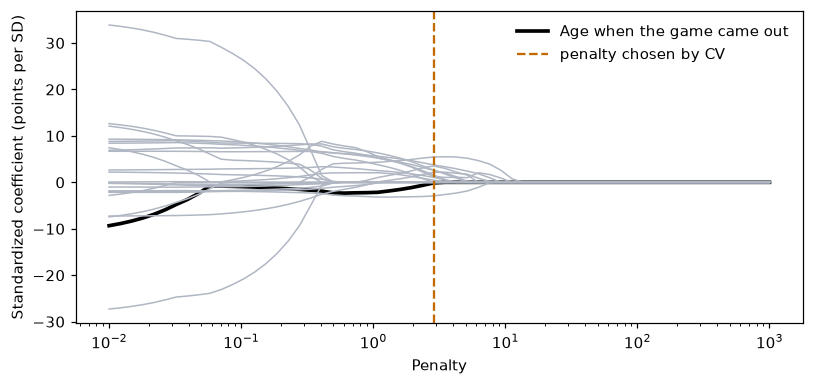

In [6]:
pens, coefs, _ = lasso_path(Z, y - y.mean(), alphas=PENALTIES[::-1])
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for j, name in enumerate(ALL):
    ax.plot(pens, coefs[j], color="black" if name == "age_game" else "#B0B7C3", lw=2.4 if name == "age_game" else 1,
            label="Age when the game came out" if name == "age_game" else None)
lasso_fit = lasso().fit(X, y)
ax.axvline(lasso_fit[-1].alpha_, color="#C26A00", ls="--", label="penalty chosen by CV")
ax.set(xscale="log", xlabel="Penalty", ylabel="Standardized coefficient (points per SD)")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

kept = pd.Series(lasso_fit[-1].coef_, index=ALL)
print(f"Penalty chosen on all 57 films: {lasso_fit[-1].alpha_:.2f}")
print(f"Kept {int((kept != 0).sum())} of {len(ALL)}:", kept[kept != 0].round(2).to_dict())
print("Standardized coefficient on age when the game came out:", round(kept["age_game"], 2))
with warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)      # the chosen penalty must converge cleanly
    make_pipeline(StandardScaler(), LassoCV(alphas=[lasso_fit[-1].alpha_], cv=5, max_iter=50_000)).fit(X, y)
score[f"Lasso, all {len(ALL)}"] = cv_rmse(lasso, ALL)
print(f"{'Lasso, all ' + str(len(ALL)):26} held-out RMSE {score[f'Lasso, all {len(ALL)}'].mean():5.2f}")

Before reading the kept list as "what matters", check whether it would come back on another sample.
Draw 200 bootstrap samples of the 57 films (Topic 7: 57 films drawn with replacement, so some appear
twice and some not at all), refit lasso on each, and count how often each feature is kept.

In [7]:
rng = np.random.default_rng(0)
times_kept = pd.Series(0, index=ALL)
for b in range(200):
    i = rng.integers(0, len(y), len(y))
    m = lasso().fit(X.iloc[i], y[i])
    times_kept += (m[-1].coef_ != 0)
share_kept = (times_kept / 200).sort_values(ascending=False)
print("Share of 200 bootstrap samples in which lasso keeps the feature:")
print(share_kept.round(2).to_string())

Share of 200 bootstrap samples in which lasso keeps the feature:
dist_Warner       0.94
dist_20th         0.89
budget_missing    0.87
year_sq           0.84
dist_Sony         0.79
dist_Paramount    0.78
pub_Ubisoft       0.78
year              0.72
pub_Sega          0.68
log_budget        0.62
animated          0.60
anim_x_age        0.58
lag_sq            0.56
pub_Sony          0.50
age_game          0.48
age_x_year        0.42
later_film        0.42
dist_Universal    0.40
anim_x_year       0.40
pub_Capcom        0.36
pub_Eidos         0.35
lag               0.23
age_sq            0.22


A feature kept in nearly every sample is a stable choice. Most of these are kept in some samples and
dropped in others: with 57 films, which variables lasso picks depends on which films happen to be in
the sample. The kept list is a prediction device, not a finding about what drives a film's score.

## Part 5: The Scorecard

The same 20 shuffles for every model, so the comparison is paired: on each shuffle, did ridge on all
features beat the midterm model?

In [8]:
table = pd.DataFrame({"held-out RMSE": {k: v.mean() for k, v in score.items()},
                      "lowest of 20": {k: v.min() for k, v in score.items()},
                      "highest of 20": {k: v.max() for k, v in score.items()}}).round(2)
print(table.sort_values("held-out RMSE").to_string())
ridge_wins = (score[f"Ridge, all {len(ALL)}"] < score["OLS, midterm model (3)"]).mean()
print(f"Ridge on all {len(ALL)} beats the midterm OLS model in {ridge_wins:.0%} of the 20 shuffles")

                          held-out RMSE  lowest of 20  highest of 20
Ridge, all 23                     19.22         18.60          20.82
Ridge, midterm model (3)          20.16         19.49          20.48
OLS, midterm model (3)            20.24         19.48          20.61
Lasso, all 23                     21.93         20.04          24.29
Predict the average               24.53         24.24          24.89
OLS, all 23                       26.71         21.92          67.14
Ridge on all 23 beats the midterm OLS model in 85% of the 20 shuffles


## Part 6: How to Fake a Better Model

Add one more feature: the film's Metacritic score. It is a different site, but it is still critics
reviewing the same film at the same time, so it is published when the Rotten Tomatoes score is. A model
that uses it is not predicting anything a studio could know before release. This is **leakage**
(Topic 15, again in Topic 18), and it is the easiest way to produce an impressive scorecard.

In [9]:
X["metacritic"] = films["metacritic"].fillna(films["metacritic"].median())
leak = cv_rmse(ols, MAIN + ["metacritic"])
X = X.drop(columns="metacritic")
print(f"Films with a Metacritic score: {films['metacritic'].notna().sum()} of {len(films)}")
print(f"Midterm model + Metacritic: held-out RMSE {leak.mean():.2f}  (midterm model alone: {score['OLS, midterm model (3)'].mean():.2f})")

Films with a Metacritic score: 52 of 57
Midterm model + Metacritic: held-out RMSE 14.30  (midterm model alone: 20.24)


The error falls by far more than any penalty in this notebook managed, because the feature is close to
another copy of the outcome. When a new variable improves a model a lot, ask first when it was measured.

## Part 7: Back to the Midterm Question

Part 4 printed lasso's coefficient on age when the game came out. That number answers
"does age help predict the score, once the other kept features are in?", not "what happens to the score
when the director is younger?". A penalty also biases every coefficient toward zero on purpose, and the
standard errors OLS reports do not apply after a data-driven selection. So lasso's own coefficient is
not an estimate to report.

What lasso can do for the causal question is **choose the controls**. Post-double-selection (it returns
in Topic 24) runs lasso twice: once to find what predicts the score, once to find what predicts age.
Every variable picked in either step is kept as a control, release year and format are kept whatever lasso
says, because the midterm's graph requires them, and then plain OLS with robust standard errors (HC1, Topic 14)
estimates the age coefficient. The question is which candidates lasso may choose from.

Distributor is the least safe item on the graph's list: a studio picks its director after the distribution deal,
but a small film is often sold to a distributor after it is finished. That is why the next cell also reports the
list without it.

In [10]:
def double_selection(candidates):
    W = X[candidates]
    def picks(target):
        m = make_pipeline(StandardScaler(), LassoCV(alphas=PENALTIES, cv=10, max_iter=50_000, random_state=0)).fit(W, target)
        return set(W.columns[m[-1].coef_ != 0])
    controls = sorted(picks(y) | picks(X["age_game"].to_numpy()) | {"year", "animated"})
    fit = sm.OLS(y, sm.add_constant(X[["age_game"] + controls])).fit(cov_type="HC1")
    lo, hi = fit.conf_int().loc["age_game"]
    return fit.params["age_game"], lo, hi, controls

AGE_TERMS = ["age_game", "age_sq", "anim_x_age", "age_x_year"]
everything = [c for c in ALL if c not in AGE_TERMS]
dag_allowed = ["year", "year_sq", "animated", "anim_x_year", "later_film"] + [c for c in ALL if c.startswith(("pub_", "dist_"))]
main = sm.OLS(y, sm.add_constant(X[MAIN])).fit(cov_type="HC1")
rows = [("Midterm model (OLS)", main.params["age_game"], *main.conf_int().loc["age_game"], MAIN[1:])]
rows.append(("Lasso picks from everything", *double_selection(everything)))
rows.append(("Lasso picks from the DAG's list", *double_selection(dag_allowed)))
for name, b, lo, hi, controls in rows:
    print(f"{name:32} age {b:+.2f} (95% CI {lo:+.2f} to {hi:+.2f})  controls: {len(controls)}")
    print(f"{'':32} {', '.join(controls)}")

# Which candidates move the answer? Take one group out of each list at a time.
BUDGET, LAG = ["log_budget", "budget_missing"], ["lag", "lag_sq"]
variants = {"everything, without budget": [c for c in everything if c not in BUDGET],
            "everything, without lag": [c for c in everything if c not in LAG],
            "graph's list, no distributors": [c for c in dag_allowed if not c.startswith("dist_")],
            "graph's list, no studio dummies": [c for c in dag_allowed if not c.startswith(("pub_", "dist_"))]}
print()
for name, cands in variants.items():
    b, lo, hi, _ = double_selection(cands)
    print(f"{name:32} age {b:+.2f} (95% CI {lo:+.2f} to {hi:+.2f})")
    variants[name] = (b, lo, hi)

Midterm model (OLS)              age -0.30 (95% CI -0.79 to +0.19)  controls: 2
                                 year, animated
Lasso picks from everything      age -0.58 (95% CI -1.14 to -0.02)  controls: 12
                                 animated, budget_missing, dist_20th, dist_Paramount, dist_Warner, lag, lag_sq, log_budget, pub_Capcom, pub_Ubisoft, year, year_sq
Lasso picks from the DAG's list  age -0.21 (95% CI -0.59 to +0.17)  controls: 10
                                 animated, dist_20th, dist_Paramount, dist_Sony, dist_Warner, pub_Capcom, pub_Sega, pub_Ubisoft, year, year_sq

everything, without budget       age -0.37 (95% CI -0.96 to +0.21)
everything, without lag          age -0.09 (95% CI -0.47 to +0.29)
graph's list, no distributors    age -0.09 (95% CI -0.68 to +0.50)
graph's list, no studio dummies  age -0.17 (95% CI -0.67 to +0.34)


Look at the middle row first. It is the only interval in this notebook that leaves zero, and it is the
result a specification search would stop at. Now look at what lasso chose to get it: the budget, which the
midterm's causal graph calls a possible mediator, and `lag`, which is part of X itself (holding `lag` fixed
turns age at the game into age at release). Lasso picks a variable because it predicts, and it has no idea
what a mediator is. Neither control does it alone: with lag but no budget the estimate is −0.37 (−0.96 to
+0.21), and with budget but no lag it is −0.09 (−0.47 to +0.29). Only the pair pushes the interval past zero,
and with both in the coefficient answers a different question from the midterm's, so its interval is not
evidence for the hypothesis as written.

Restricted to the controls the graph allows (release year, format, the franchise flag, publisher and
distributor), double selection gives −0.21; without the distributor dummies it gives −0.09, and with no
studio dummies at all −0.17. The estimate moves with the list, the conclusion does not: every one of these
intervals includes zero. With 57 films and ten controls the intervals are approximate, so read them as a
sign, not a decimal.

**What to take from this notebook**

- A penalty improves prediction: ridge beats the midterm model on films it has not seen, and OLS on every
  feature loses to the average.
- A penalty does not identify anything. The data choose which variables predict; the causal graph
  decides which ones may be controls. Choose the candidates first, then let lasso choose among them.
- The one interval that leaves zero comes from controls the graph rules out. Trying estimators until
  one does is a specification search. What would narrow the valid interval is more films, or a better
  measure of who played the game.